# LAPIS candidate Sérsic morphology

Inspect each saved simultaneous fit using the satellite morphology workflow: convergence diagnostics, a shared-morphology corner plot, and data/model/residual images with radial profiles. This notebook reads existing results and does not run inference.


In [1]:
from pathlib import Path

import asdf
import corner
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import smplotlib
from astropy.io import fits
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from IPython.display import Markdown, display

from gordian.helpers import get_const_param, get_model_from_tree
from gordian.loading import load_observation
from gordian.plotting import plot_imaging_profile_grid
from gordian.tree import get_model_config, get_observation_ids


In [2]:
PROJECT_DIR = Path("/Users/Jonah/PhD/Research/lapis")
SIGHTLINE = "lwf"
RUN_NAME = "sersic"
METHOD = "mcmc"

OUT_BASE = PROJECT_DIR / "outputs" / "gordian_outputs" / SIGHTLINE
FIG_BASE = PROJECT_DIR / "figures" / "gordian_outputs" / SIGHTLINE
RESULT_NAME = f"sersic_{METHOD}_simultaneous_results.asdf"
OBJECTS = sorted(path.name for path in OUT_BASE.glob("*") if (path / RUN_NAME / RESULT_NAME).is_file())
# Set OBJECTS explicitly above the loop to inspect a subset, e.g. ["ID003"].


In [3]:
# Empirical PSF FWHM in arcsec (F150W2 is simulated)
PSF_FWHM = {
    "F150W2": 0.045,
    "F200W": 0.066,
    "F210M": 0.071,
    "F277W": 0.092,
    "F356W": 0.116,
    "F444W": 0.145,
}

SIZE = 10  # Size of cutout images in pixels
R_MAX = np.sqrt(SIZE**2 + SIZE**2)  # Use the valid image extent for each radial profile
DPI = 200
PRETTY_LABELS = {
    "xc": r"$x_c$",
    "yc": r"$y_c$", 
    "theta": r"$\Theta$", 
    "ellip": r"$\epsilon$", 
    "r_eff": r"$R_{\rm e}\,\rm{[pix]}$", 
    "n": r"$n$",
    }

For each object, the corner plot shows the saved shared morphology posterior (positions and radius in pixels, angle in radians). Models use the posterior median image with fitted fluxes; radial-profile geometry uses MAP parameters, matching the reference notebook. Pixel scales come from the saved science WCS. Figures are saved as PDF and PNG under `figures/gordian_outputs/<sightline>/<object>/<run>/`.


## ID001

Included bands: F150W2, F200W, F210M, F277W, F356W, F444W


,ess_bulk,ess_tail,mcse_mean,mcse_sd,r_hat
ellip,1295.0,891.0,0.001,0.001,1.00
flux_F150W2,756.0,1177.0,0.001,0.001,1.00
flux_F200W,1256.0,1322.0,0.002,0.002,1.00
flux_F210M,1717.0,1553.0,0.003,0.002,1.00
flux_F277W,524.0,905.0,0.002,0.001,1.00
flux_F356W,475.0,808.0,0.003,0.002,1.00
flux_F444W,423.0,605.0,0.008,0.005,1.00
n,483.0,606.0,0.058,0.044,1.01
r_eff,556.0,657.0,0.005,0.003,1.00
sky_back_F150W2,2083.0,1172.0,0.000,0.000,1.00


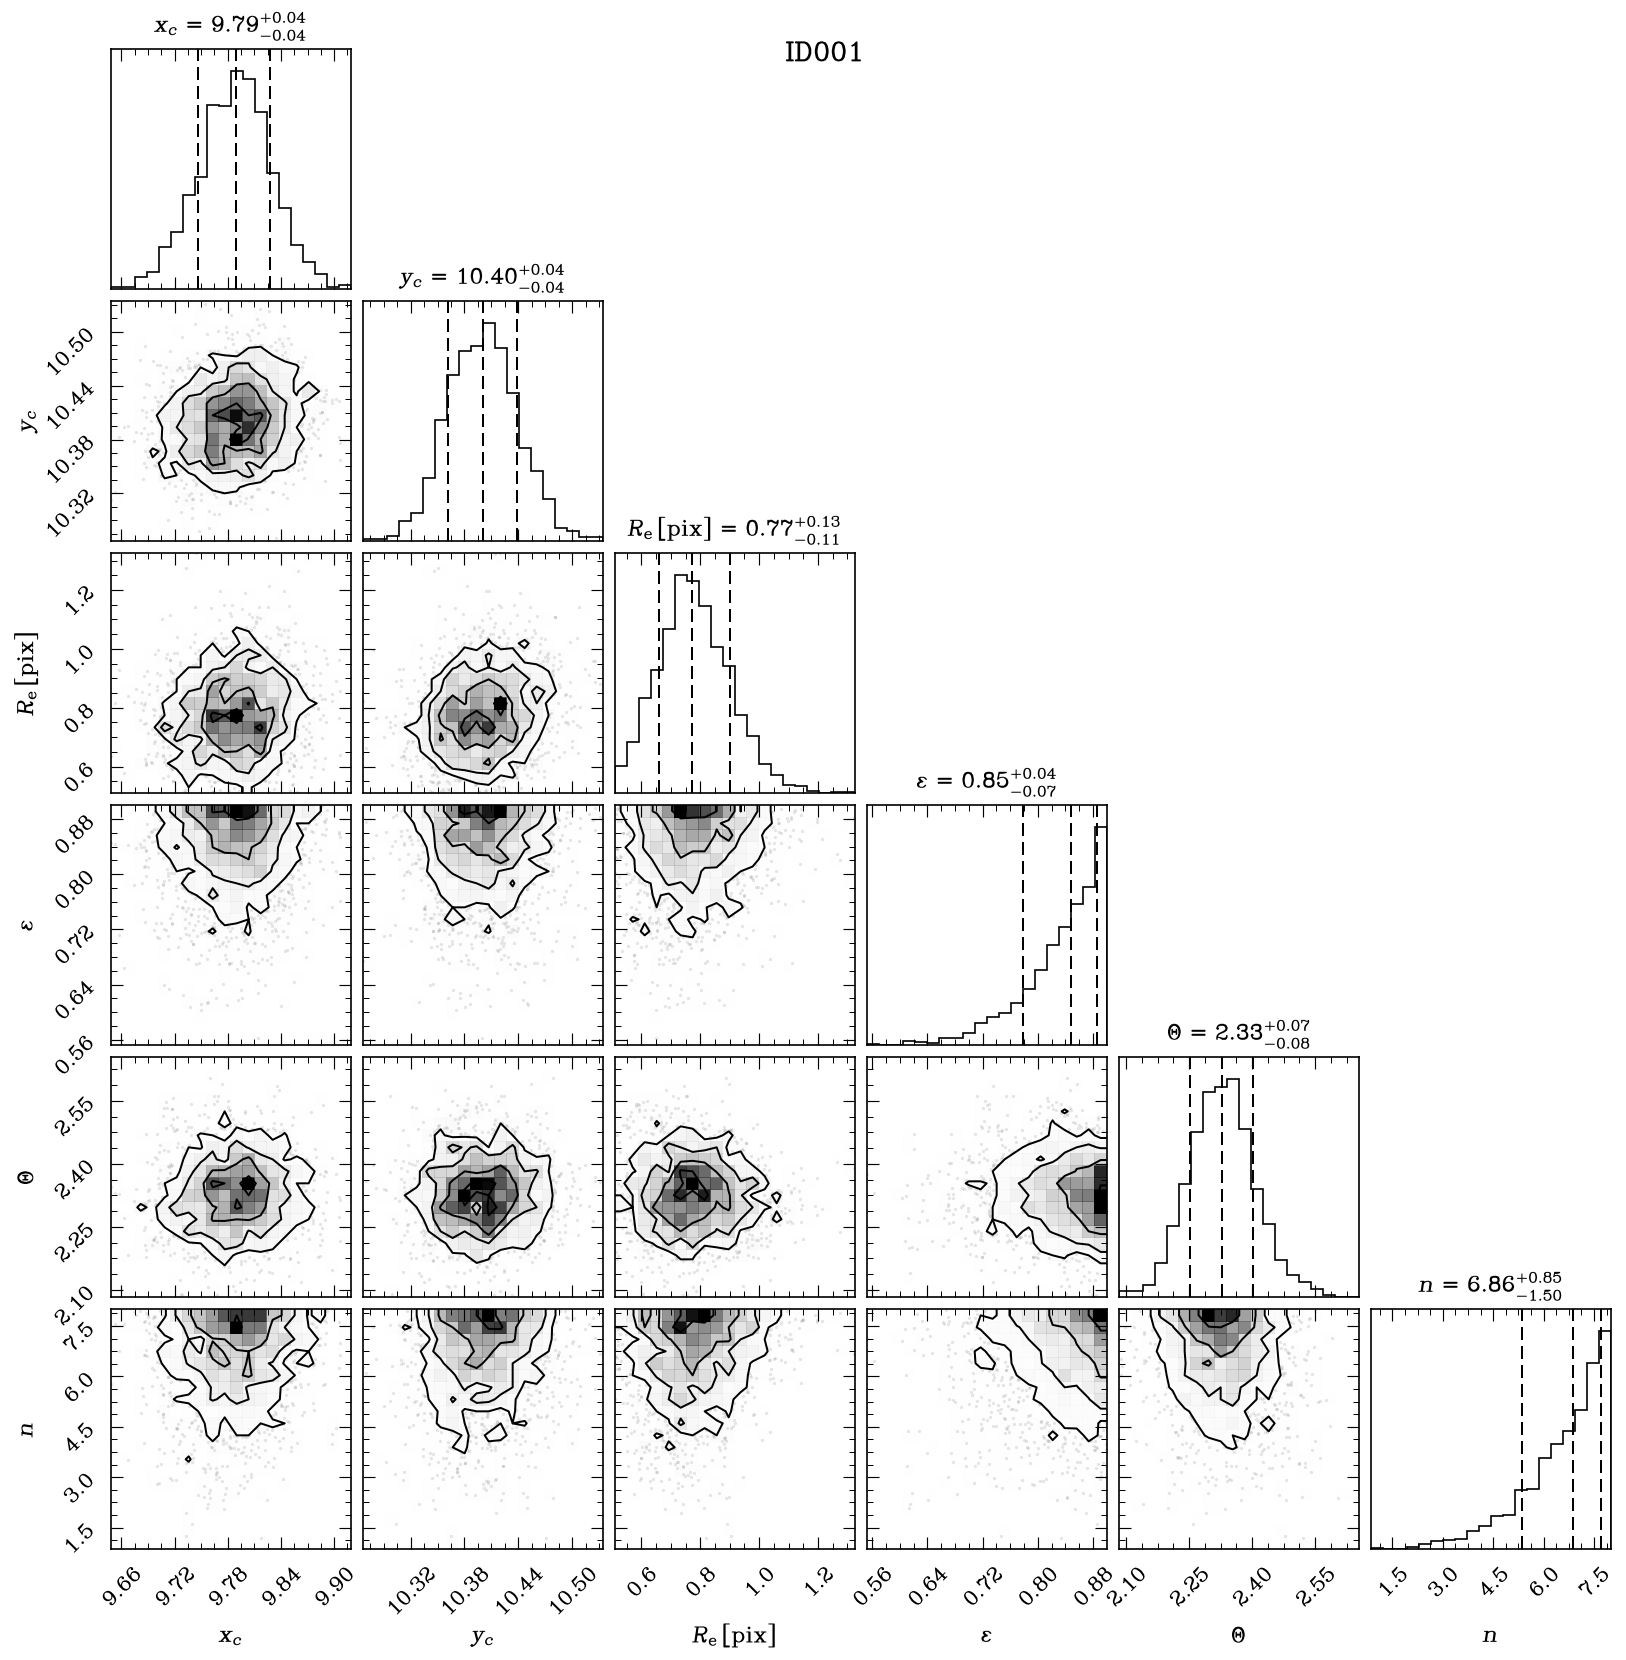

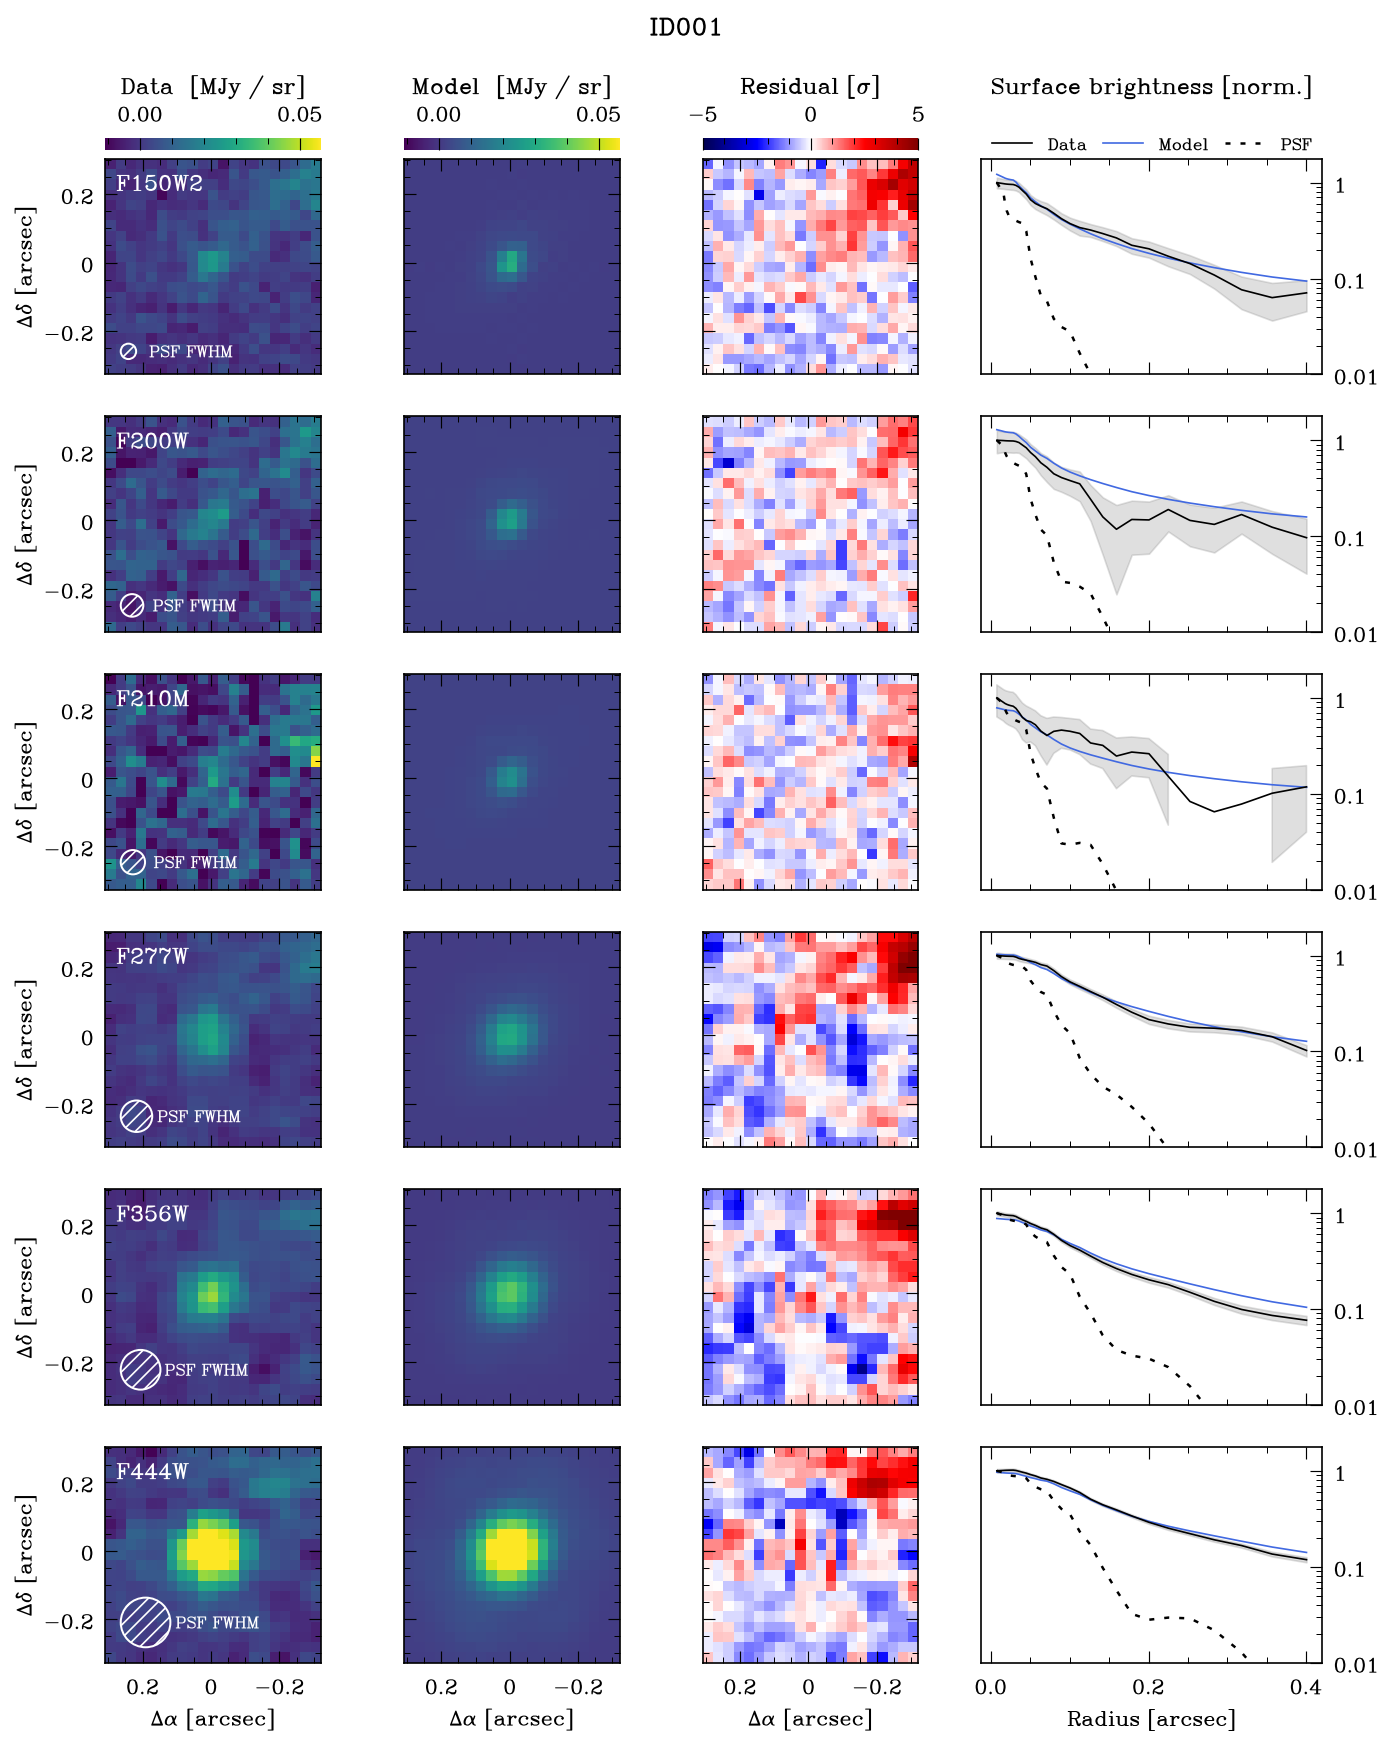

## ID002

Included bands: F150W2, F200W, F210M, F277W, F356W, F444W


,ess_bulk,ess_tail,mcse_mean,mcse_sd,r_hat
ellip,1481.0,1332.0,0.001,0.001,1.00
flux_F150W2,1523.0,1265.0,0.001,0.001,1.01
flux_F200W,1625.0,1455.0,0.002,0.002,1.00
flux_F210M,1614.0,1612.0,0.003,0.003,1.00
flux_F277W,1169.0,1424.0,0.001,0.001,1.00
flux_F356W,1151.0,1317.0,0.002,0.001,1.00
flux_F444W,1056.0,1247.0,0.003,0.002,1.00
n,1162.0,984.0,0.004,0.004,1.00
r_eff,935.0,1118.0,0.002,0.001,1.00
sky_back_F150W2,1748.0,1158.0,0.000,0.000,1.00


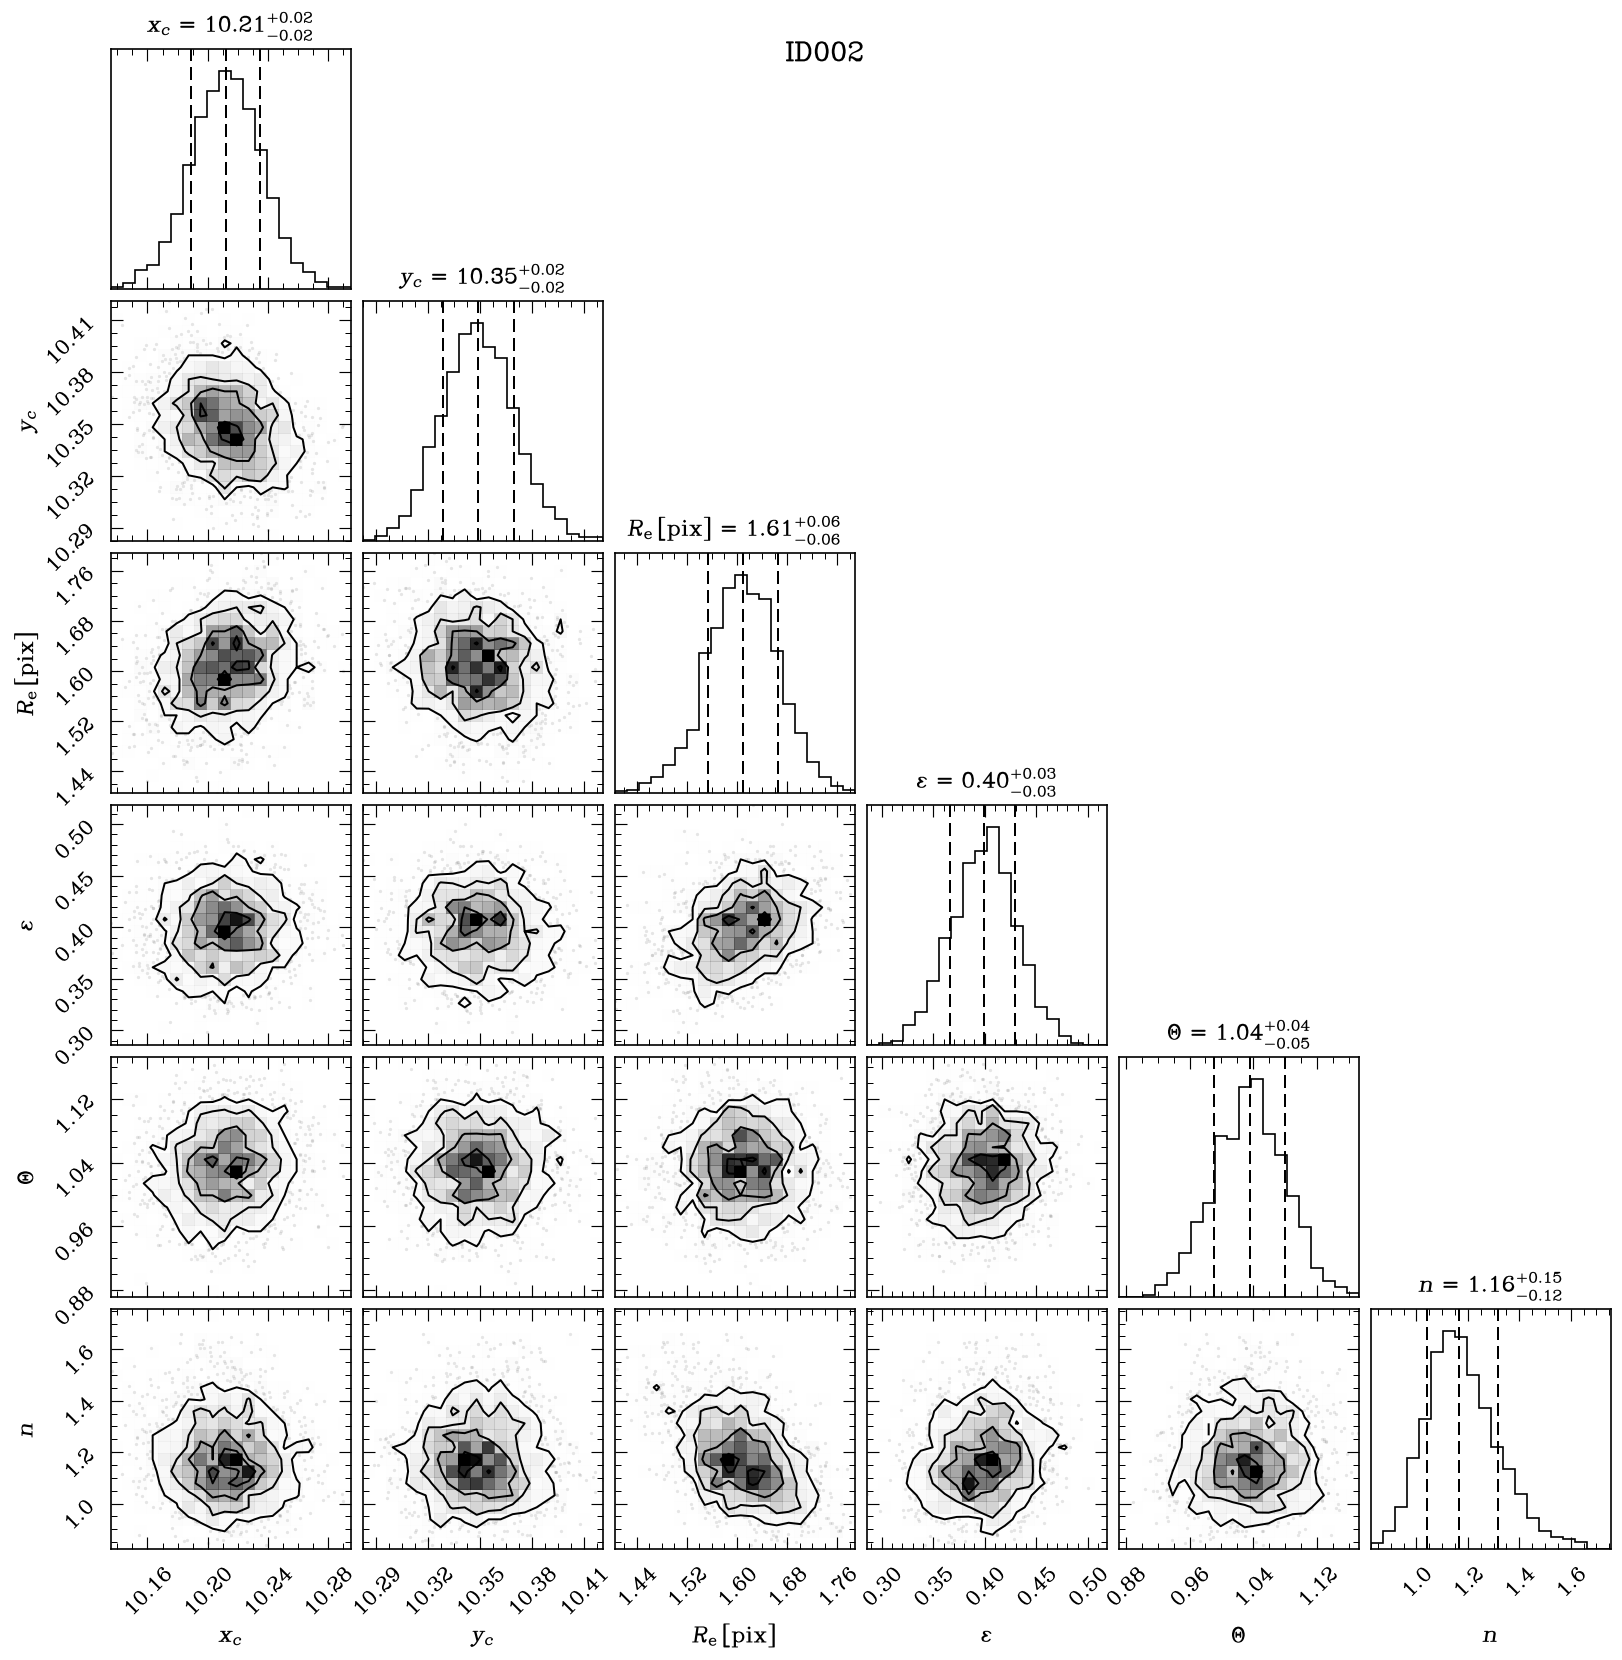

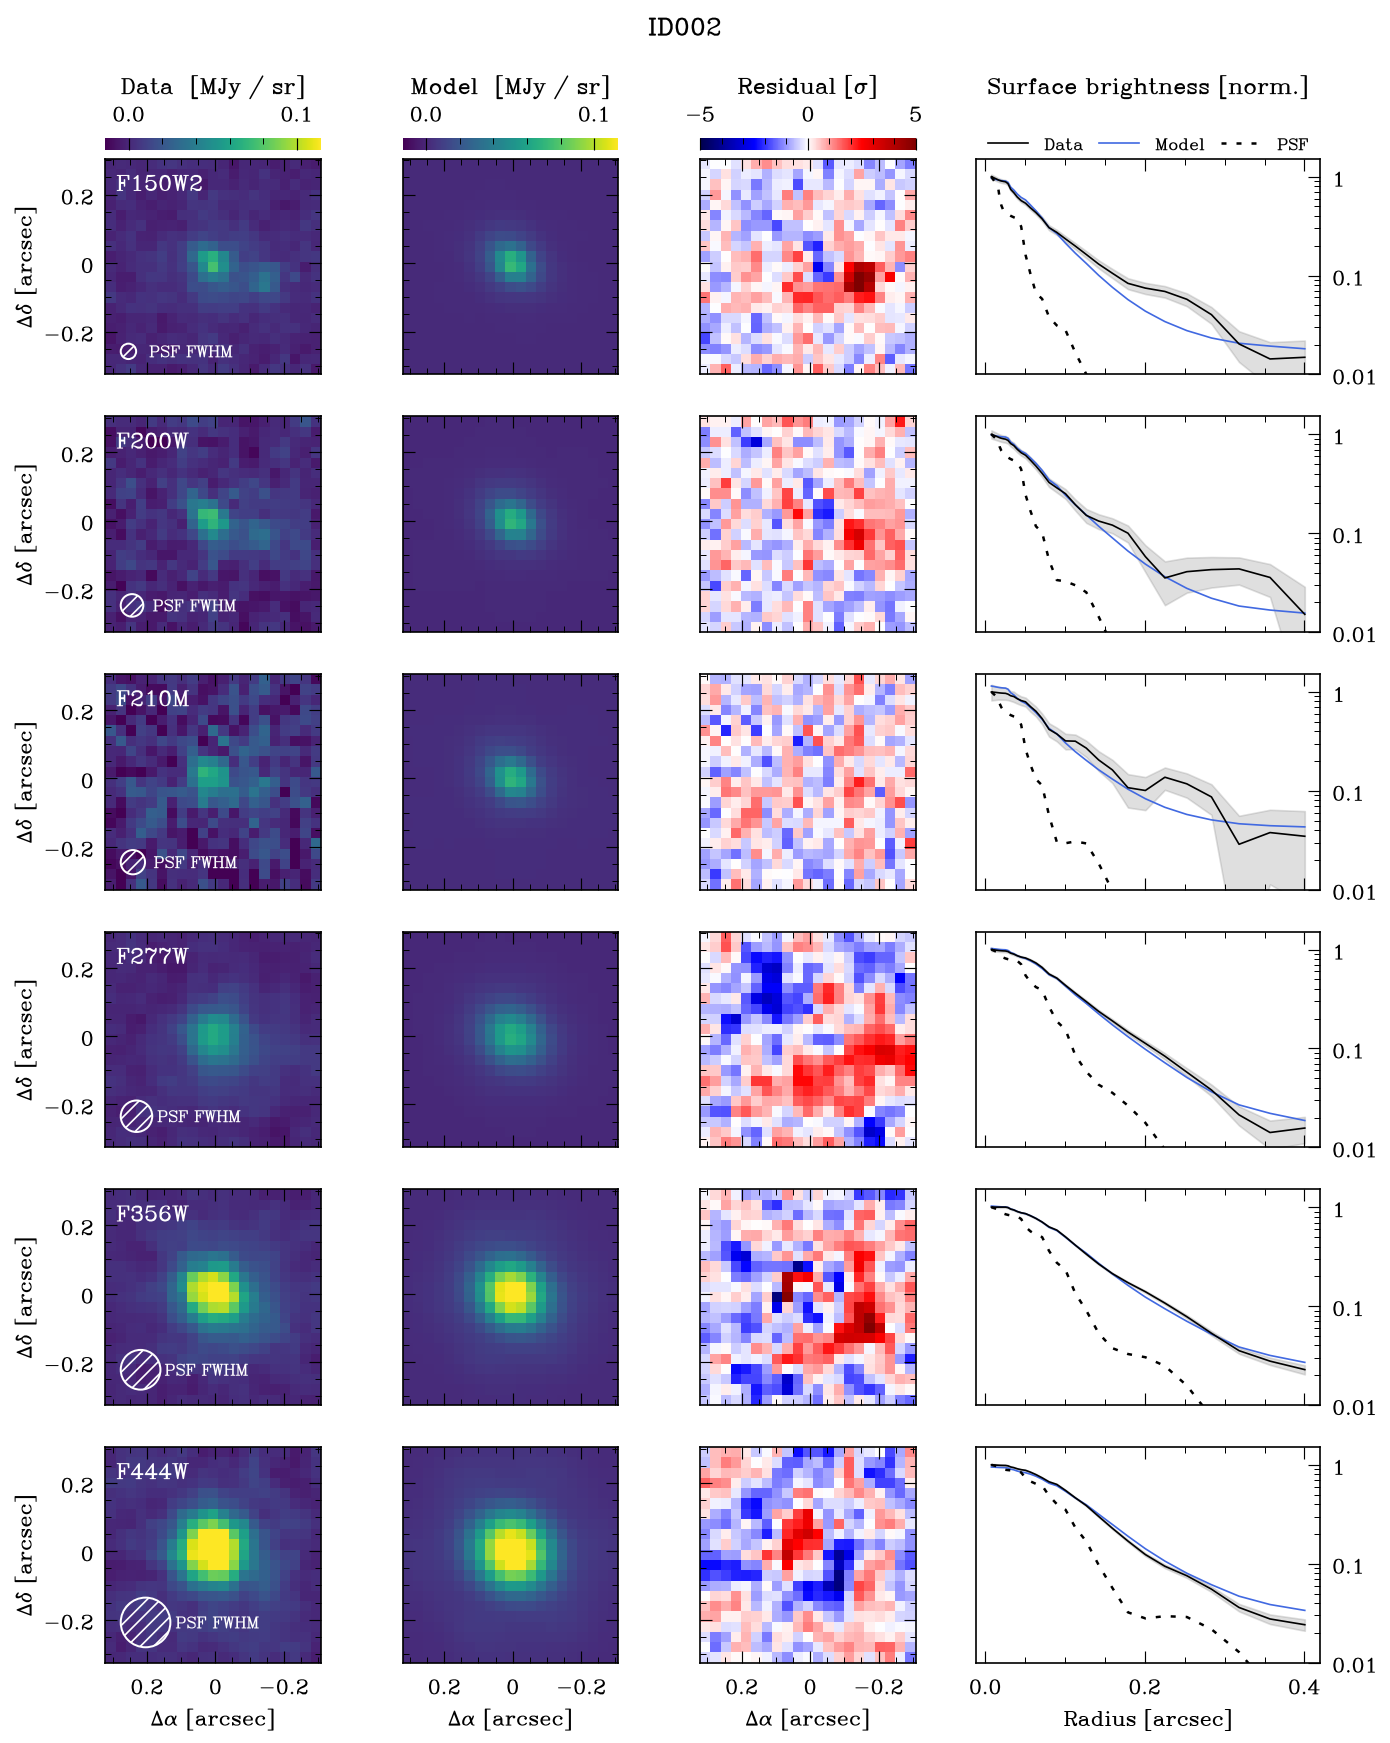

## ID003

Included bands: F150W2, F200W, F210M, F277W, F356W, F444W


,ess_bulk,ess_tail,mcse_mean,mcse_sd,r_hat
ellip,1244.0,1394.0,0.000,0.000,1.00
flux_F150W2,1999.0,1334.0,0.004,0.004,1.01
flux_F200W,1860.0,1430.0,0.004,0.004,1.00
flux_F210M,1876.0,1504.0,0.005,0.005,1.00
flux_F277W,794.0,1146.0,0.002,0.001,1.00
flux_F356W,816.0,982.0,0.005,0.003,1.00
flux_F444W,762.0,1080.0,0.004,0.002,1.00
n,798.0,1296.0,0.002,0.001,1.00
r_eff,1005.0,1376.0,0.001,0.001,1.00
sky_back_F150W2,1992.0,1265.0,0.000,0.000,1.01


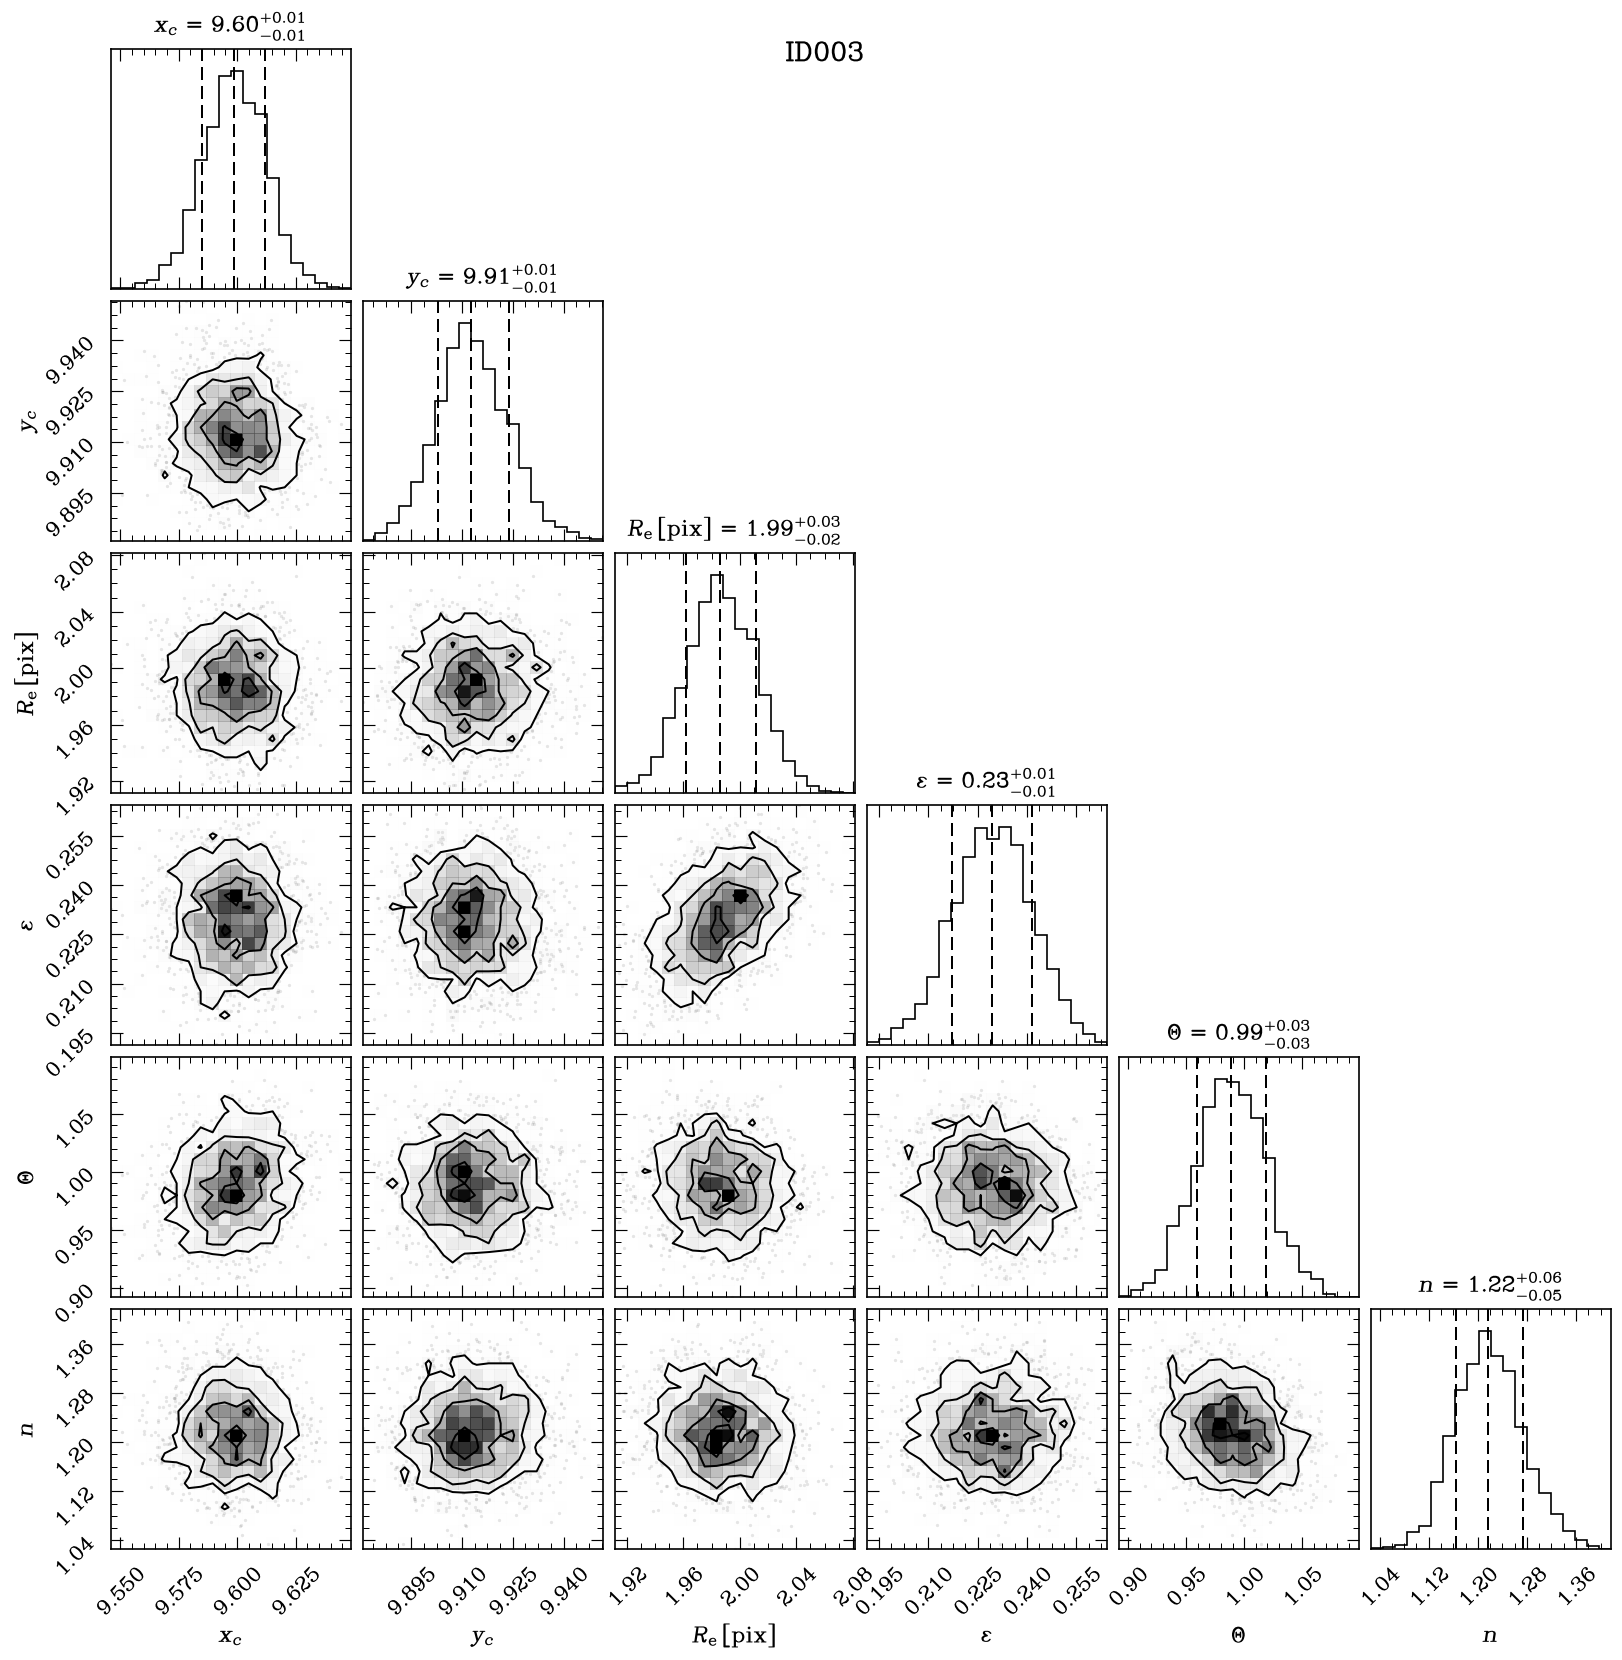

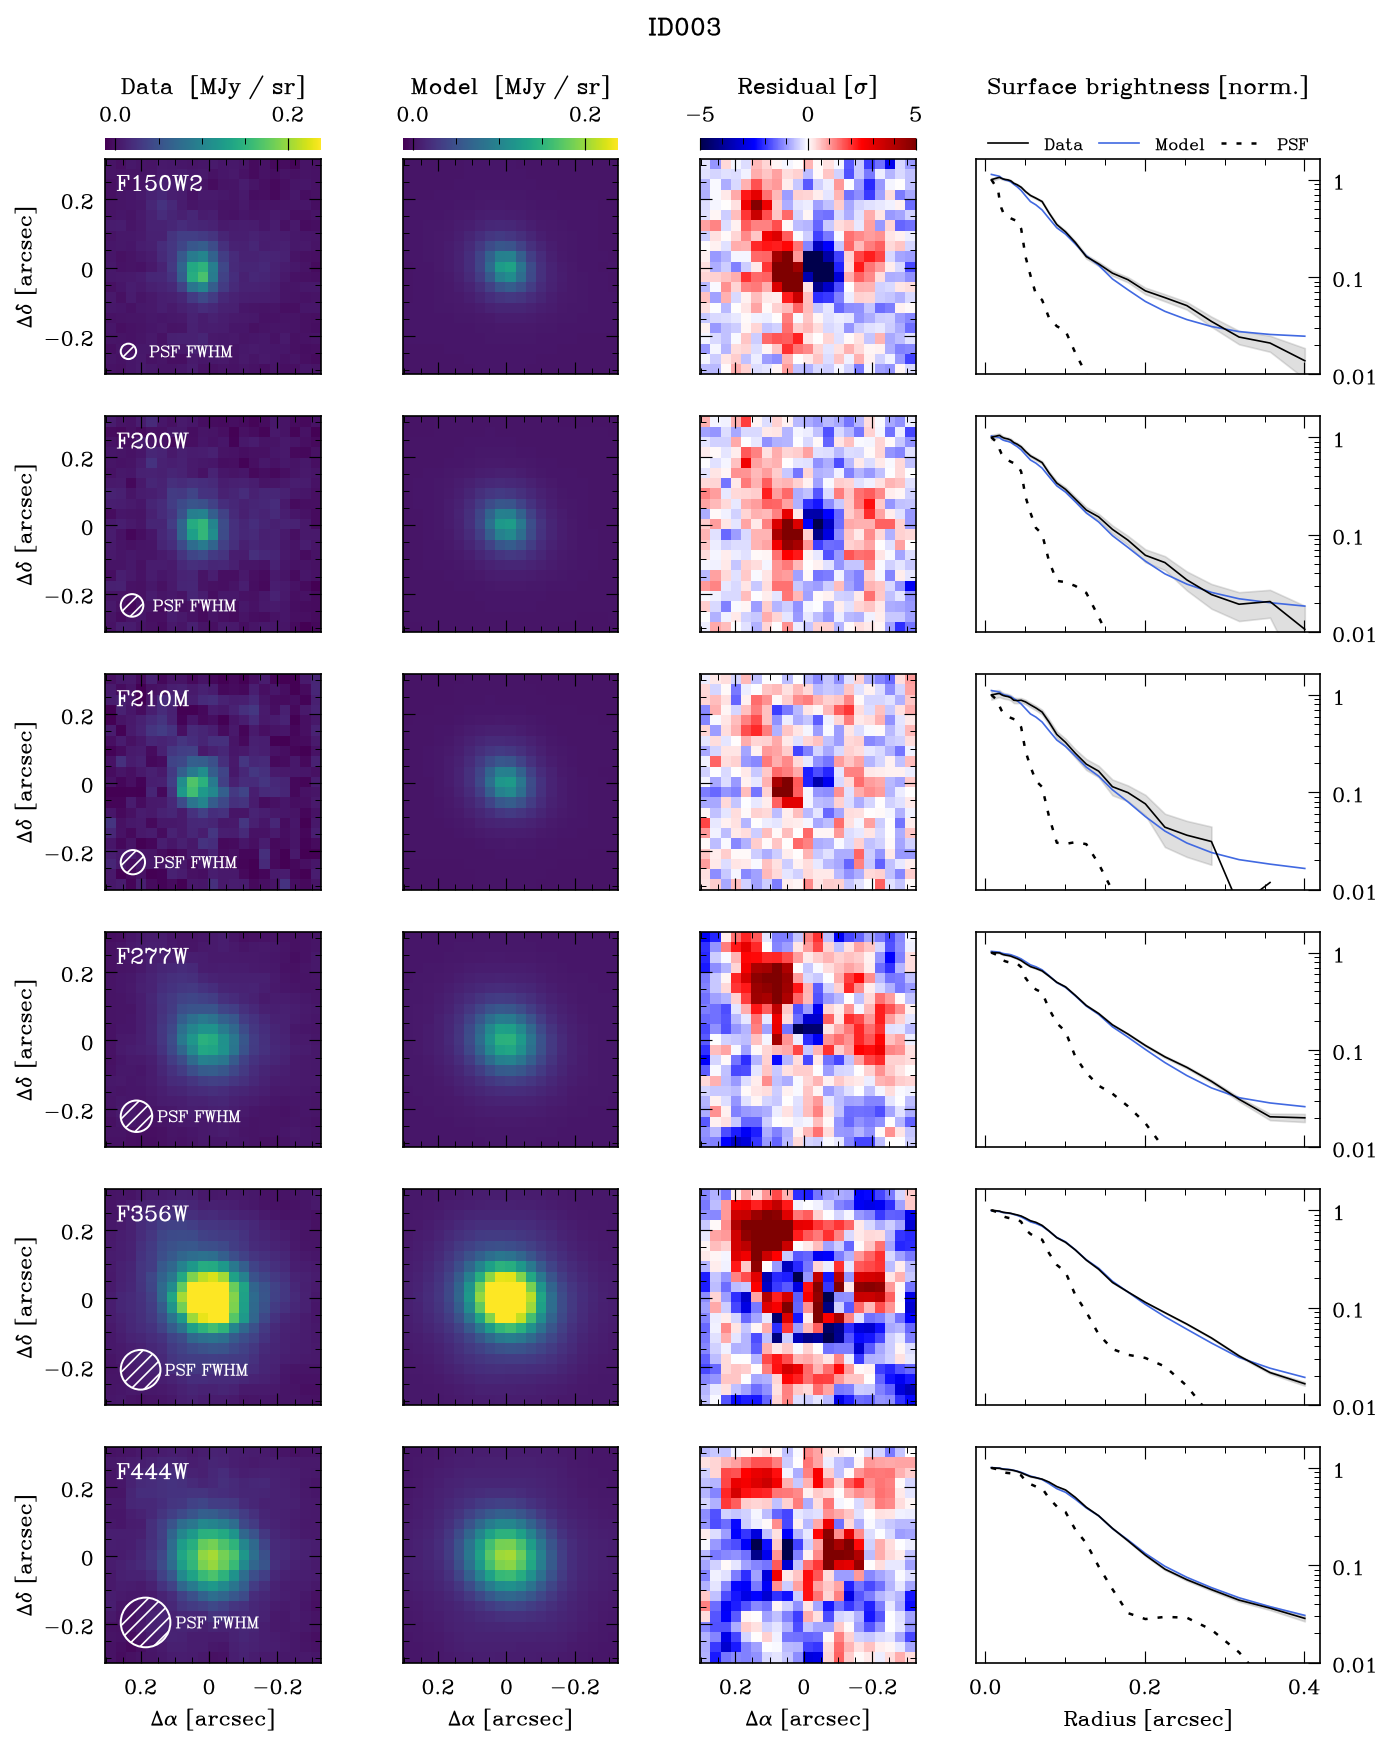

## ID004

Included bands: F150W2, F200W, F210M, F277W, F356W, F444W


,ess_bulk,ess_tail,mcse_mean,mcse_sd,r_hat
ellip,677.0,516.0,0.003,0.002,1.0
flux_F150W2,682.0,1214.0,0.001,0.001,1.0
flux_F200W,967.0,1158.0,0.002,0.001,1.0
flux_F210M,1545.0,1391.0,0.002,0.002,1.0
flux_F277W,318.0,1122.0,0.007,0.002,1.0
flux_F356W,339.0,1141.0,0.011,0.003,1.0
flux_F444W,331.0,980.0,0.012,0.003,1.0
n,287.0,756.0,0.007,0.006,1.0
r_eff,662.0,583.0,0.002,0.001,1.0
sky_back_F150W2,1913.0,1333.0,0.000,0.000,1.0


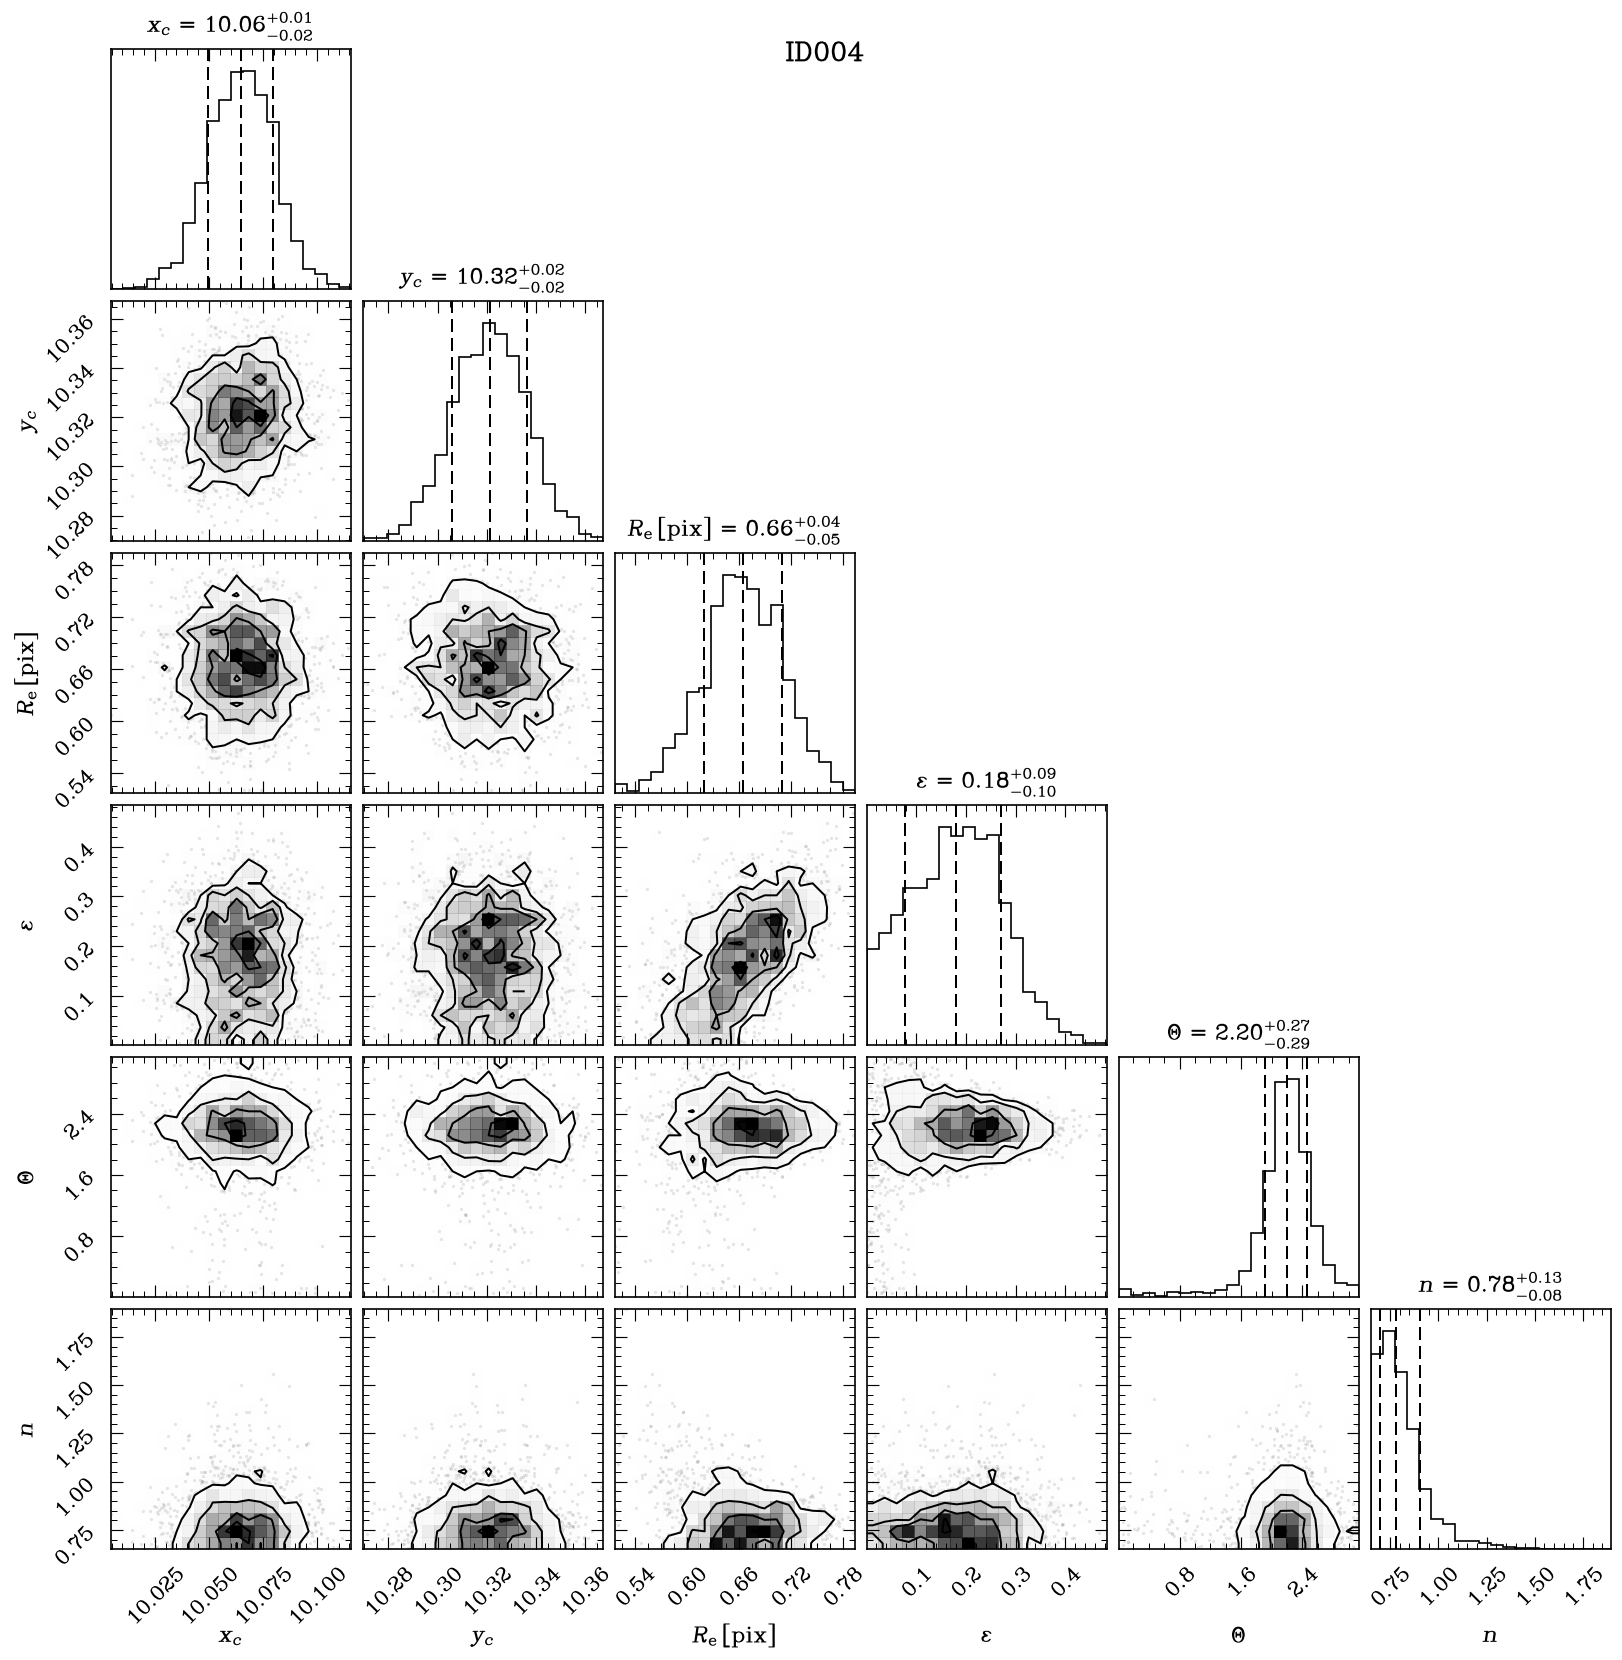

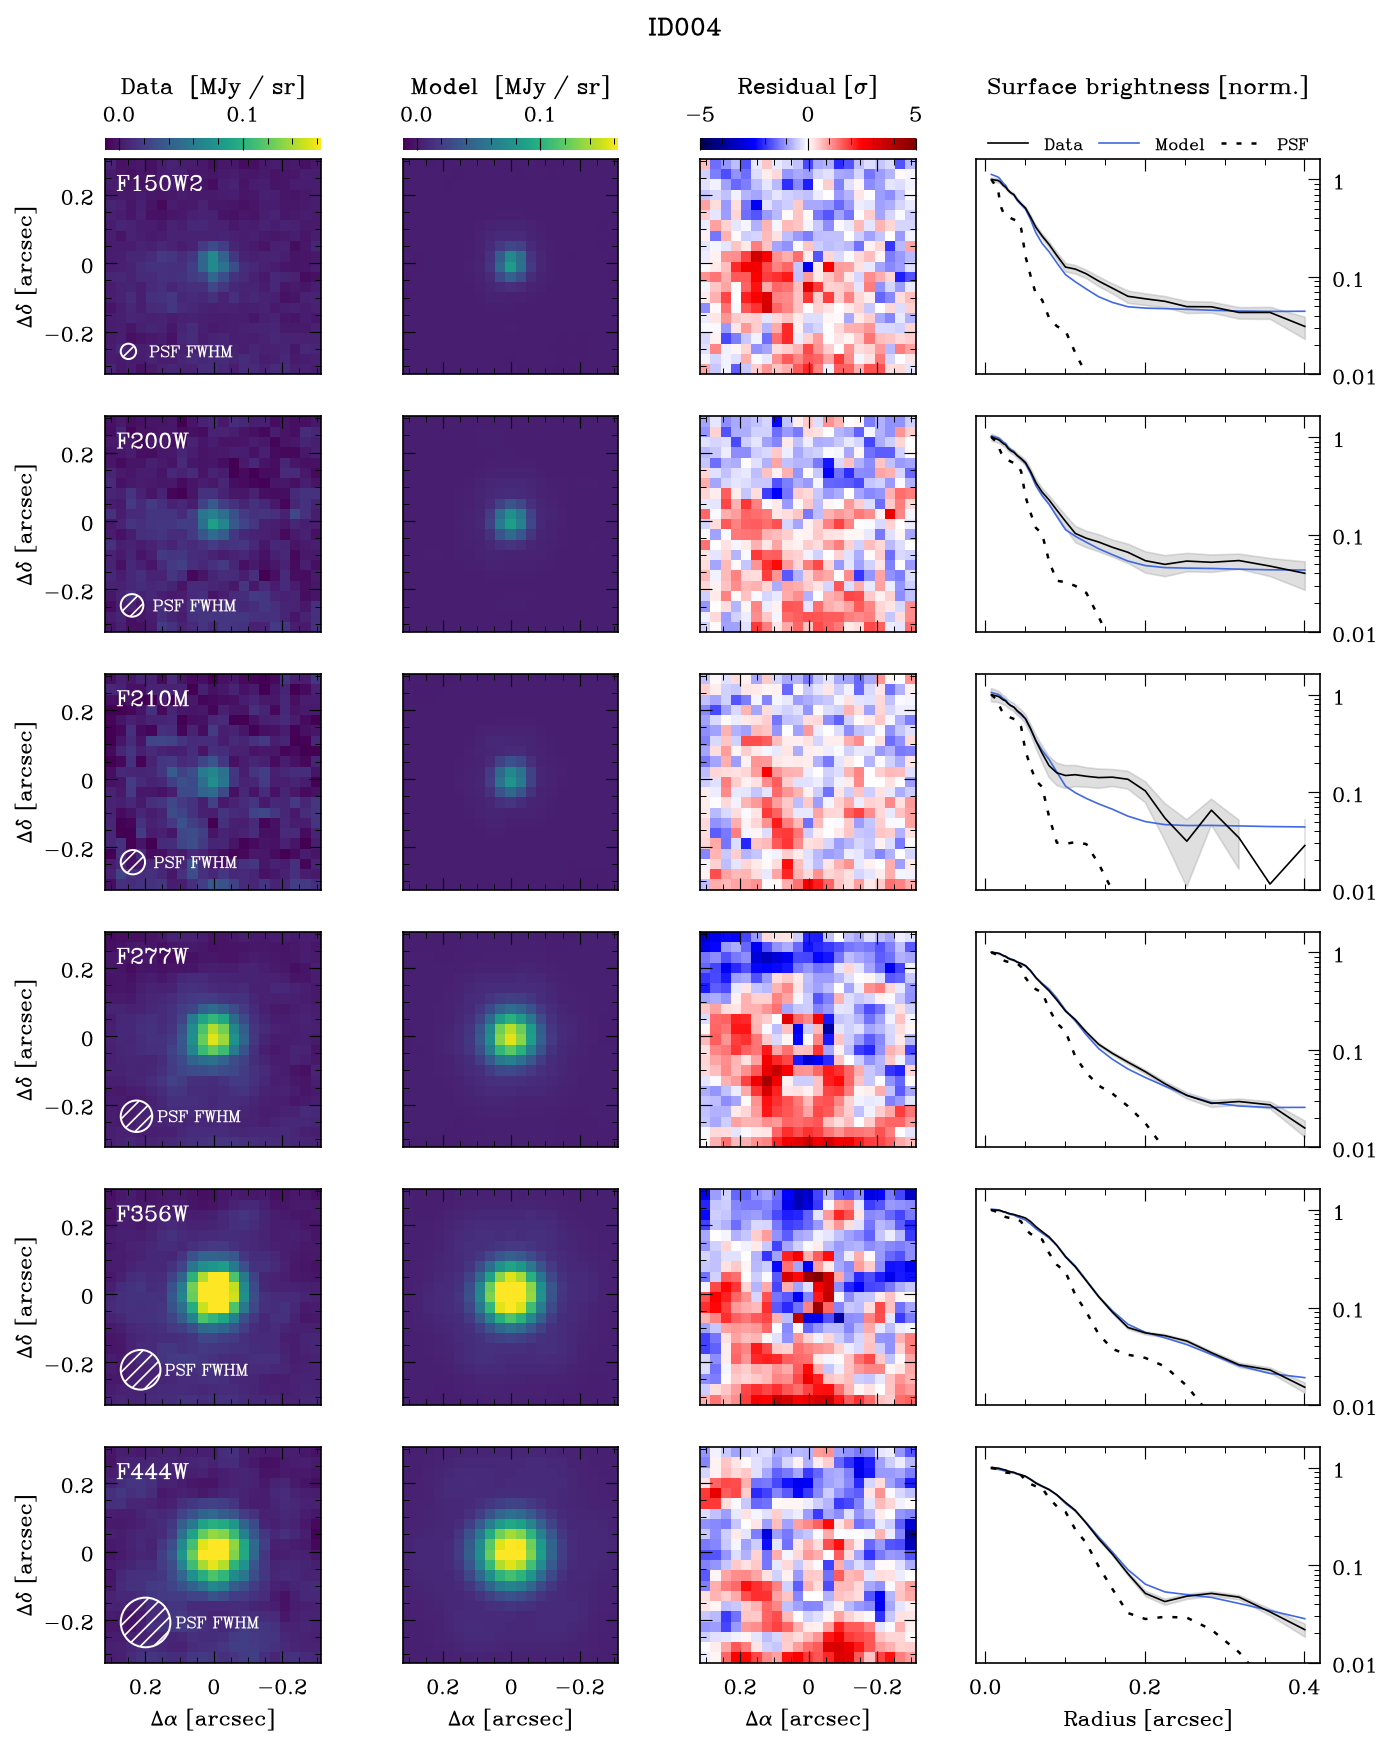

In [6]:
for object_name in OBJECTS:
    result_path = OUT_BASE / object_name / RUN_NAME / RESULT_NAME
    fig_dir = FIG_BASE / object_name / RUN_NAME
    fig_dir.mkdir(parents=True, exist_ok=True)
    display(Markdown(f"## {object_name}"))

    with asdf.open(result_path) as result_file:
        tree = result_file.tree
        results = tree["results"]
        model_config = get_model_config(tree)
        observation_ids = get_observation_ids(tree)
        samples = results["samples"]
        print(f"Included bands: {', '.join(observation_ids)}")
        display(pd.DataFrame.from_dict(results["convergence"]["by_param"], orient="index"))

        morphology_params = [param for param in model_config.const_params if param in samples]
        morphology_samples = np.column_stack([samples[param] for param in morphology_params])
        morphology_labels = [PRETTY_LABELS.get(param, param) for param in morphology_params]
        fig = corner.corner(morphology_samples, labels=morphology_labels, quantiles=[0.16, 0.5, 0.84], show_titles=True, title_fmt=".2f", title_kwargs={"fontsize": 16}, label_kwargs={"fontsize": 16})
        fig.suptitle(f"{object_name}", fontsize=20)
        fig.savefig(fig_dir / f"sersic_{METHOD}_simultaneous_morphology_corner.pdf", bbox_inches="tight")
        fig.savefig(fig_dir / f"sersic_{METHOD}_simultaneous_morphology_corner.png", dpi=DPI, bbox_inches="tight")
        plt.show()
        plt.close(fig)

        observations = {}
        models = {}
        geometries = {}
        pixel_scales = {}
        for observation_id in observation_ids:
            loaded = load_observation(tree, observation_id)
            observations[observation_id] = loaded
            models[observation_id] = get_model_from_tree(
                tree, observation_id=observation_id, mode="posterior_median", use_image_flux=False, observation=loaded,
            )
            geometries[observation_id] = {
                param: float(get_const_param(tree, param=param, mode="map"))
                for param in ("xc", "yc", "theta", "ellip")
            }
            science_header = fits.Header.fromstring(loaded.metadata["data"]["header"])
            science_wcs = WCS(science_header, fix=False).celestial
            pixel_scales[observation_id] = float(np.nanmean(np.abs(proj_plane_pixel_scales(science_wcs))) * 3600.0)

        fig = plot_imaging_profile_grid(observations, models, geometries, pixel_scales=pixel_scales, psf_fwhm=PSF_FWHM, r_max=R_MAX)
        fig.suptitle(f"{object_name}")
        fig.tight_layout()
        fig.savefig(fig_dir / f"sersic_{METHOD}_simultaneous_imaging_profiles.pdf", bbox_inches="tight")
        fig.savefig(fig_dir / f"sersic_{METHOD}_simultaneous_imaging_profiles.png", dpi=DPI, bbox_inches="tight")
        plt.show()
        plt.close(fig)
